<h1 align="center">LNR_LAB_6: Transformers and Explainability</h2>
<h3 style="display:block; margin-top:5px;" align="center">Natural Language and Information Retrieval</h3>
<h3 style="display:block; margin-top:5px;" align="center">Degree in Data Science</h3>
<h3 style="display:block; margin-top:5px;" align="center">ETSInf. Universitat Politècnica de València</h3>
<br>

### Put your names here

- Alejandro de las Nieves Duro

### CONSTANTS

In [1]:
COLAB = True # IF YOU USE GOOGLE COLAB -> COLAB = True
PIP = True # IF YOU NEED INSTALL LIBRARIES -> PIP = True

**If you have trouble installing ferret-xai or jsonnet on Linux, try installing these packages first:**

- sudo apt install cmake   
- sudo apt install g++     
- sudo apt install make

**Or that after installing ferret-xai:**

- conda install -c conda-forge libstdcxx-ng --update-deps


## Some libraries

In [2]:
!pip install "setuptools<82"
!pip install -U jupyter ipywidgets
!pip install -U ferret-xai shap lime
!pip install sentencepiece



  Using cached shap-0.51.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (25 kB)


In [3]:
import os
import sys
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import pandas as pd
from typing import List, Tuple
#from datasets import Dataset
import tqdm

In [4]:
if COLAB is True:
  from google.colab import drive
  drive.mount('/content/drive')
  base_path = "/content/drive/MyDrive/LNR/"
else:
  base_path = "../"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Read the dataset

In [5]:
# Load the development sets for subtask 2.1 and subtask 2.2 and for each language. The same development sets used in previous labs.

from pathlib import Path

P5_MODELS_DIR = Path(base_path) / "P5" / "models"
P5_RESULTS_DIR = Path(base_path) / "P5" / "results"
P6_OUTPUT_DIR = Path(base_path) / "P6" / "outputs"

P6_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EN_TASK21_MODEL_DIR = P5_MODELS_DIR / "en_21_full_finetuning" / "model"
ES_TASK21_MODEL_DIR = P5_MODELS_DIR / "es_21_full_finetuning" / "model"

EN_TASK21_PREDICTIONS = P5_MODELS_DIR / "en_21_full_finetuning" / "dev_predictions.csv"
ES_TASK21_PREDICTIONS = P5_MODELS_DIR / "es_21_full_finetuning" / "dev_predictions.csv"

en_dev_predictions = pd.read_csv(EN_TASK21_PREDICTIONS)
es_dev_predictions = pd.read_csv(ES_TASK21_PREDICTIONS)

print("English dev predictions:", en_dev_predictions.shape)
print("Spanish dev predictions:", es_dev_predictions.shape)

display(en_dev_predictions.head())
display(es_dev_predictions.head())

print("English model path:", EN_TASK21_MODEL_DIR)
print("Spanish model path:", ES_TASK21_MODEL_DIR)


English dev predictions: (401, 5)
Spanish dev predictions: (396, 5)


,id_EXIST,text,gold_label,predicted_label,correct
0,211082,SMASH OR PASS ifunny.co,YES,NO,False
1,210338,YOU KNOW WHAT REALLY GRINDS MY GEARS? T REALLY...,NO,NO,True
2,211440,them: e why would you like him?? he looks like...,YES,YES,True
3,211523,REALLY? ONLY 4 INCHES? imgflip.com,YES,NO,False
4,210357,Which of the following is the largest? 8 An El...,NO,NO,True


,id_EXIST,text,gold_label,predicted_label,correct
0,110774,día? DiaDelHombre,NO,NO,True
1,110661,Cuando el paciente al que le acabas de inventa...,NO,NO,True
2,110125,Abusar de niños Michael Jackson Michael Jackson,NO,NO,True
3,110471,Violador:*entra a una celda* Los demas prision...,NO,NO,True
4,111853,Nadie te va a tratar tan bien como un hombre q...,YES,YES,True


English model path: /content/drive/MyDrive/LNR/P5/models/en_21_full_finetuning/model
Spanish model path: /content/drive/MyDrive/LNR/P5/models/es_21_full_finetuning/model


In [6]:
display(en_dev_predictions.head())
display(es_dev_predictions.head())

,id_EXIST,text,gold_label,predicted_label,correct
0,211082,SMASH OR PASS ifunny.co,YES,NO,False
1,210338,YOU KNOW WHAT REALLY GRINDS MY GEARS? T REALLY...,NO,NO,True
2,211440,them: e why would you like him?? he looks like...,YES,YES,True
3,211523,REALLY? ONLY 4 INCHES? imgflip.com,YES,NO,False
4,210357,Which of the following is the largest? 8 An El...,NO,NO,True


,id_EXIST,text,gold_label,predicted_label,correct
0,110774,día? DiaDelHombre,NO,NO,True
1,110661,Cuando el paciente al que le acabas de inventa...,NO,NO,True
2,110125,Abusar de niños Michael Jackson Michael Jackson,NO,NO,True
3,110471,Violador:*entra a una celda* Los demas prision...,NO,NO,True
4,111853,Nadie te va a tratar tan bien como un hombre q...,YES,YES,True


## Dataset class

In [7]:
class SexismDataset(Dataset):
    def __init__(self, texts, labels, ids, tokenizer, max_len=128, pad="max_length", trunc=True,rt='pt'):
        self.texts = texts.tolist()
        self.labels = labels
        self.ids = ids
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.pad = pad
        self.trunc = trunc
        self.rt = rt

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        inputs = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,padding=self.pad, truncation=self.trunc,
            return_tensors=self.rt
        )

        return {
            'input_ids': inputs['input_ids'].flatten(),
            'attention_mask': inputs['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
            'id': torch.tensor(self.ids[idx], dtype=torch.long)
        }

## Auxiliary functions

In [8]:
from collections import Counter # Counter counts the number of occurrences of each item
from itertools import tee, count

def uniquify(seq, suffs = count(1)):
    """Make all the items unique by adding a suffix (1, 2, etc).

    `seq` is mutable sequence of strings.
    `suffs` is an optional alternative suffix iterable.
    """
    not_unique = [k for k,v in Counter(seq).items() if v > 1] # so we have: ['name', 'zip']
    # suffix generator dict - e.g., {'name': <my_gen>, 'zip': <my_gen>}
    suff_gens = dict(zip(not_unique, tee(suffs, len(not_unique))))
    for idx,s in enumerate(seq):
        try:
            suffix = str(next(suff_gens[s]))
        except KeyError:
            # s was unique
            continue
        else:
            seq[idx] += suffix

def deduplicate(explanations):
    for i in range(len(explanations)):
        tokens = explanations[i].tokens
        uniquify(tokens, (f'_{x!s}' for x in range(1, 100)))
        explanations[i].tokens=tokens
    return explanations

In [9]:
#Select the device to run the model on (GPU if available, otherwise CPU)
device = "cpu"
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")

# Two options to predict

### The simplest

In [10]:
def predict_op1(model, dataset, args = {}):

    # Set up the Trainer, yes, a trainer for prediction!
    training_args = TrainingArguments(
        output_dir="./output",
        per_device_eval_batch_size = args.get("per_device_eval_batch_size", 16),
        do_train=False,
        do_eval=False,
    )
    trainer = Trainer(model=model, args=training_args)

    # Predict
    predictions = trainer.predict(dataset)

    # Get logits, shape = #samples, num_classes (2)
    logits = predictions.predictions

    # Compute probability with softmax, requires logits to be tensors (unnecessary to compute the class)
    probs = torch.nn.functional.softmax(torch.tensor(logits), dim=-1).numpy()
    probs2 = np.max(probs, axis=-1)

    # Get the predicted class using argmax
    pred_classes = np.argmax(logits, axis=-1)
    # equals to: pred_classes = np.argmax(probs, axis=-1)

    return pred_classes, probs2

### The coolest, if you know what you're doing

In [11]:
def predict_op2(model, dataset, args = {}):
    # batch_size
    batch_size = args.get("per_device_eval_batch_size", 16)

    model.to(device)
    # Set eval model, no gradient stored
    model.eval()

    # Prepare DataLoader
    dataloader = DataLoader(dataset, batch_size=batch_size)

    # Prediction loop
    logits_list = []
    with torch.no_grad():
        for batch in tqdm.notebook.tqdm(dataloader):
            del batch["id"]
            batch = {k: v.to(device) for k, v in batch.items()}
            # equals to: outputs = model.forward(**batch)
            outputs = model(**batch)
            logits_list.append(outputs.logits)

    # Concatenate and move logits to the CPU, shape = #samples, num_classes (2)
    logits = torch.cat(logits_list, dim=0).cpu()

    # Compute probability with softmax, requires logits to be tensors (unnecessary to compute the class)
    probs = torch.nn.functional.softmax(logits, dim=-1).numpy()
    probs2 = np.max(probs, axis=-1)

    # Get the predicted class using argmax
    pred_classes = np.argmax(logits, axis=-1).numpy()
    # equals to: pred_classes = np.argmax(probs, axis=-1).numpy()


    return pred_classes, probs2


### Predictions from the best English model

In [12]:
# English Task 2.1 model from Practice 5

print(en_dev_predictions.columns)

tokenizer = AutoTokenizer.from_pretrained(str(EN_TASK21_MODEL_DIR))

model = AutoModelForSequenceClassification.from_pretrained(
    str(EN_TASK21_MODEL_DIR)
)

# Dataset
val_dataset = SexismDataset(
    en_dev_predictions["text"],
    LabelEncoder().fit_transform(en_dev_predictions["gold_label"]),
    [int(x) for x in en_dev_predictions["id_EXIST"]],
    tokenizer
)

# Predictions
preds, probs = predict_op1(model, val_dataset)

# Verify both prediction methods give same output
y_pred1, probs1 = predict_op1(model, val_dataset)
y_pred2, probs2 = predict_op2(model, val_dataset)

print("Both methods equal:", all(x1 == x2 for x1, x2 in zip(y_pred1, y_pred2)))

Index(['id_EXIST', 'text', 'gold_label', 'predicted_label', 'correct'], dtype='object')


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  0%|          | 0/26 [00:00<?, ?it/s]

Both methods equal: True


### Evaluation of the results

In [13]:
def compute_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary'
    )
    acc = accuracy_score(y_true, y_pred)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall,
    }

# Metrics
metrics = compute_metrics(val_dataset.labels, preds)
print("Metrics:", metrics)

# Confusion matrix
conf_matrix = confusion_matrix(val_dataset.labels, preds)#, labels=["NO", "YES"])
print("\nConfusion matrix:")
print(conf_matrix)

# Classification report
class_report = classification_report(val_dataset.labels, preds, target_names=["NO", "YES"], digits=4)
print("\nReport:")
print(class_report)

Metrics: {'accuracy': 0.6533665835411472, 'f1': 0.6273458445040214, 'precision': 0.65, 'recall': 0.6062176165803109}

Confusion matrix:
[[145  63]
 [ 76 117]]

Report:
              precision    recall  f1-score   support

          NO     0.6561    0.6971    0.6760       208
         YES     0.6500    0.6062    0.6273       193

    accuracy                         0.6534       401
   macro avg     0.6531    0.6517    0.6517       401
weighted avg     0.6532    0.6534    0.6526       401



### Plot confusion matrix


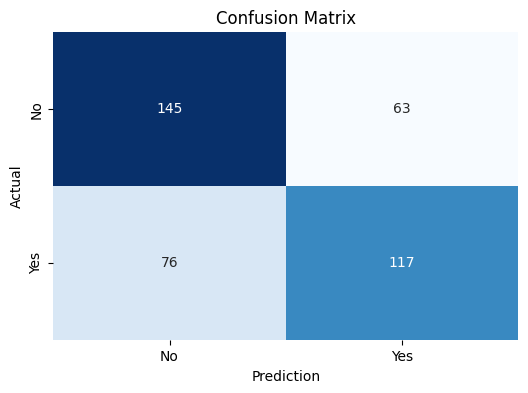

In [14]:
#!pip install matplotlib seaborn --upgrade
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No", "Yes"],
            yticklabels=["No", "Yes"])
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

### Text and probability of False positive and False negative

In [15]:
def false_positive_false_negative(
    y_true: List[int],
    y_pred: List[int],
    pred_probs: List[float],
    texts: List[str]
) -> Tuple[List[Tuple[float, str]], List[Tuple[float, str]]]:

    """
    Returns incorrect predictions from a binary classification model.

    Parameters:
    - y_true (list[int]): True labels for each sample (0 or 1).
    - y_pred (list[int]): Labels predicted by the model (0 or 1).
    - pred_probs (list[float]): Probabilities assigned by the model.
    - texts (list[str]): Text of each sample.

    Returns:
    - false_positives
    - false_negatives
    """

    false_positive = []
    false_negative = []

    for true_label, predicted_label, probability, text in zip(
        y_true,
        y_pred,
        pred_probs,
        texts
    ):

        # False Positive: predicted YES but actually NO
        if true_label == 0 and predicted_label == 1:
            false_positive.append((probability, text))

        # False Negative: predicted NO but actually YES
        elif true_label == 1 and predicted_label == 0:
            false_negative.append((probability, text))

    return false_positive, false_negative

In [16]:
fpositive, fnegative = false_positive_false_negative(y_true = val_dataset.labels, y_pred = preds, pred_probs = probs, texts = val_dataset.texts)

print("False positive:", len(fpositive))
for s in fpositive:
    print('**', s)

print("\n\nFalse negative:", len(fnegative))
for s in fnegative:
    print('**', s)

False positive: 63
** (0.753174, 'I LIKE MY WOMEN LIKE I LIKE MY COFFEE STRONG AND GIVEN PROPER CREDIT FOR THEIR CONTRIBUTIONS IN BOTH THE HOME AND THE WORKPLACE memecrunch.co')
** (0.6616882, "Boys vs girls memes are funny!! This template can be enjoyed by both men and women No they're just cringe and sexist Yes.")
** (0.5180891, 'Most super models a random girl on the street that one girl in the class you always got a problem with **')
** (0.83325607, "THAT'S CORRECT, I SAID SEENUS PROBLEM-NOT SINUS PROBLEM IWAS OUT WITH ANOTHER WOMAN AND MY GIRLFRIEND SEEN US НЕЕК imgilip.com")
** (0.69989395, 'This is Feminism. Sorry for being a man who enjoys pineapple on pizza Some crimes can never be forgiven')
** (0.81581646, "TODAYS INTERNATIONAL WOMEN'S DAY!! DAT OK CAUSE IT BE INTERNATIONAL MEN'S DAY EVERY OTHER DAY imgflip.com")
** (0.6295541, 'The "Earth" without "art" is just "eh". 14 year old girls, middle-aged women, mods:')
** (0.57487524, '†† DO & DONT LIST: +4 tt 帅帅 XX<<< NO YOU FCKI

### Select some samples to analyze

You can select the samples with more confidence, those with less confidence, a mix of both, or simply the ones you consider more interesting.



**Try not to choose the same samples that I’ve selected, and Justify your decision**.


In [17]:
# Make your own selection using REAL model mistakes

fpositive_samples = [
    "I HATE POSTS SAYING 'REAL MEN DON'T HIT WOMEN' A WOMAN CAN SWING A FIST ALSO",

    "THERE'S NO SUCH THING AS 'REVERSE SEXISM'. ONLY SEXISM AGAINST MEN, AND SEXISM AGAINST WOMEN."
]

fnegative_samples = [
    "WHEN DUDES ASK 'CAN YOU COOK?' 'UMMMM CAN YOU BUILD A HOUSE?'",

    "SHOW ME YOUR TITS"
]


In [18]:
# Use Ferret to analyse the selected examples

from ferret import Benchmark
from IPython.display import display_html



In [19]:
from ferret import Benchmark
from ferret.explainers.shap import SHAPExplainer
from ferret.explainers.lime import LIMEExplainer

# Create explainers
shap = SHAPExplainer(model, tokenizer)
lime = LIMEExplainer(model, tokenizer)

# Create benchmark
bench = Benchmark(
    model=model,
    tokenizer=tokenizer,
    explainers=[shap, lime]
)

In [21]:
# Analyse selected examples

from IPython.display import display

for text in fpositive_samples + fnegative_samples:

    print("=" * 100)
    print(text)

    explanations = bench.explain(
        text,
        target=1
    )

    explanations = deduplicate(explanations)

    display(bench.show_table(explanations))

I HATE POSTS SAYING 'REAL MEN DON'T HIT WOMEN' A WOMAN CAN SWING A FIST ALSO


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,I,ĠH,ATE,ĠPOST,S,ĠSAY,ING_1,Ġ',RE,AL,ĠMEN,ĠDON,'_1,T,ĠHIT,ĠWOM_1,EN,'_2,ĠA_1,ĠWOM_2,AN,ĠCAN,ĠSW,ING_2,ĠA_2,ĠF,IST,ĠALSO
Partition SHAP,-0.03,0.00,-0.00,-0.01,0.01,-0.00,-0.00,0.00,-0.01,0.02,0.15,0.00,0.00,0.00,0.01,0.28,0.05,0.01,0.05,0.30,0.03,0.01,0.00,0.00,0.00,0.00,0.02,0.00
LIME,-0.02,-0.00,0.02,0.01,-0.00,0.00,-0.01,0.01,0.00,-0.00,0.04,0.01,0.00,0.01,0.04,0.30,0.07,0.02,-0.00,0.31,0.02,0.02,0.02,0.00,-0.01,0.00,0.05,0.01


THERE'S NO SUCH THING AS 'REVERSE SEXISM'. ONLY SEXISM AGAINST MEN, AND SEXISM AGAINST WOMEN.


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,TH,ERE,',S,ĠNO,ĠSU,CH,ĠTH,ING,ĠAS,Ġ',RE,VERS,E,ĠS_1,EX_1,ISM_1,'.,ĠONLY,ĠS_2,EX_2,ISM_2,ĠAGA_1,INST_1,ĠMEN,",",ĠAND,ĠS_3,EX_3,ISM_3,ĠAGA_2,INST_2,ĠWOM,EN,.
Partition SHAP,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.01,0.01,0.00,0.00,0.04,0.01,0.03,0.17,-0.02,0.02,0.01,0.01,0.03,0.01,0.02,0.46,0.08,-0.03
LIME,0.01,0.01,-0.02,-0.00,0.01,0.00,0.00,-0.01,-0.00,0.01,0.02,-0.01,0.00,0.02,0.01,-0.01,0.01,0.02,0.01,0.01,-0.00,0.02,0.02,0.01,0.14,-0.01,0.01,0.01,0.01,0.02,-0.01,0.02,0.45,0.07,-0.02


... (2 outputs left out)

Token,WH,EN,ĠD,UD,ES,ĠAS,K,Ġ'_1,CAN,ĠYOU_1,ĠC,OOK,?'_1,Ġ'_2,UM,MM,M,ĠCAN,ĠYOU_2,ĠBU,ILD,ĠA,ĠHOUSE,?'_2
Partition SHAP,-0.08,0.08,0.19,0.20,0.06,-0.03,-0.00,0.02,0.02,-0.00,-0.01,-0.04,0.00,0.02,0.01,0.01,0.04,0.03,-0.02,-0.03,0.04,0.02,-0.01,0.03
LIME,-0.07,0.04,0.22,0.23,0.03,-0.06,0.01,-0.02,-0.02,0.01,-0.02,-0.06,-0.02,-0.00,0.00,0.02,0.03,0.00,-0.01,-0.02,0.05,0.03,0.01,-0.03


SHOW ME YOUR TITS


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,SH,OW,ĠME,ĠYOUR,ĠT,ITS
Partition SHAP,0.05,-0.04,-0.04,0.10,0.37,0.40
LIME,0.00,0.06,0.04,-0.09,0.43,0.37


### Show explanations

### English Task 2.1 – Model Evaluation and Error Analysis

For the English version of the task, we used a transformer-based text classification model based on RoBERTa. The tokenizer was loaded using the `roberta-base` configuration, while the classification model was loaded from the fine-tuned checkpoint stored in the project directory.

The workflow followed these main steps:

1. **Dataset preparation**
   - The development dataset predictions generated in previous practices were loaded from CSV files.
   - A custom `SexismDataset` class was implemented to:
     - tokenize the input texts,
     - generate attention masks,
     - convert labels into tensors,
     - and prepare the data for PyTorch inference.

2. **Prediction pipeline**
   - Two different prediction approaches were implemented:
     - `predict_op1`: using HuggingFace `Trainer`.
     - `predict_op2`: using a manual `DataLoader` and direct inference loop with PyTorch.
   - Both approaches were tested and verified to produce identical predictions.

3. **Evaluation**
   The model was evaluated using:
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - Confusion matrix
   - Classification report

The obtained results were:

- Accuracy: **0.6534**
- Precision: **0.6500**
- Recall: **0.6062**
- F1-score: **0.6273**

Confusion Matrix:

| Actual / Predicted | NO | YES |
|---|---|---|
| NO | 145 | 63 |
| YES | 76 | 117 |

The model achieved balanced precision and recall values, although performance is still moderate. The confusion matrix shows that the classifier struggles especially with ambiguous or ironic examples.

4. **Error analysis**
   False positives and false negatives were extracted and analysed manually.

#### False Positives
Many false positives contained:
- references to feminism,
- mentions of gender roles,
- discussions involving men or women,
- ironic memes,
- or sarcastic language.

Examples:
- “MEN OF QUALITY RESPECT WOMENS EQUALITY”
- “Girls compete with each other. Women empower one another.”
- “There’s no such thing as reverse sexism.”

In many cases, the model incorrectly classified texts as sexist simply because gender-related vocabulary appeared frequently.

#### False Negatives
False negatives often included:
- implicit sexism,
- offensive humour,
- sexual objectification,
- stereotypes,
- or meme formats requiring contextual understanding.

Examples:
- “I’m not wearing any panties under the skirt...”
- “Make me a sandwich”
- “Girls: omg this place is boring / Boys: ...”

These examples suggest that the model has difficulty understanding:
- sarcasm,
- meme culture,
- indirect offensive language,
- and contextual implications.

5. **Methodological observations**
During development, several technical issues appeared:
- dependency conflicts between NumPy versions,
- incompatibilities with `jax`,
- and package conflicts after installing `ferret-xai`.

To solve this:
- the runtime session had to be restarted,
- packages were upgraded manually,
- and Google Colab environment management became necessary.

Additionally, some variables initially produced `NameError` and `KeyError` exceptions because:
- dataset columns had different names than expected,
- and some previous cells had not been executed in order.

These problems were solved by:
- verifying dataframe column names,
- adapting the code to the actual dataset structure,
- and rerunning the notebook sequentially.

6. **Interpretability preparation**
Auxiliary functions were implemented to:
- deduplicate repeated explanation tokens,
- analyse false positives and false negatives,
- and prepare samples for explainability methods using the Ferret framework.

The selected samples include both highly confident errors and ambiguous cases, allowing deeper analysis of the model’s behaviour.



For the English model, real false positive and false negative examples from the development set were analysed using Ferret with SHAP and LIME.

The explanations showed that the model mainly focuses on gender-related and sexually explicit tokens. For example, in the sentence *"I HATE POSTS SAYING REAL MEN DON'T HIT WOMEN..."*, both SHAP and LIME assigned high importance to tokens related to *men* and *women*. This helps explain why the model classified the example as sexist even though the sentence is not necessarily promoting sexism, but discussing gendered violence.

In another false positive, *"THERE'S NO SUCH THING AS REVERSE SEXISM..."*, the most relevant tokens were again related to *sexism*, *men*, and *women*. This suggests that the model tends to overpredict sexism when explicit gender terminology appears, even when the text is more argumentative than hateful.

For false negatives such as *"SHOW ME YOUR TITS"* or *"WHEN DUDES ASK CAN YOU COOK..."*, the explanations showed that the model detected some relevant tokens, but the final prediction was still incorrect. This indicates that the model sometimes fails with short, meme-like, or implicit sexist expressions, especially when the meaning depends on social context rather than only explicit vocabulary.

# DO IT IN SPANISH

In [23]:
# Spanish Task 2.1 model from Practice 5

tokenizer_es = AutoTokenizer.from_pretrained(str(ES_TASK21_MODEL_DIR))

model_es = AutoModelForSequenceClassification.from_pretrained(
    str(ES_TASK21_MODEL_DIR)
)

# Spanish validation dataset
val_dataset_es = SexismDataset(
    es_dev_predictions["text"],
    LabelEncoder().fit_transform(es_dev_predictions["gold_label"]),
    [int(x) for x in es_dev_predictions["id_EXIST"]],
    tokenizer_es
)

# Predictions
preds_es, probs_es = predict_op1(model_es, val_dataset_es)

# Verify both prediction methods give same output
y_pred1_es, probs1_es = predict_op1(model_es, val_dataset_es)
y_pred2_es, probs2_es = predict_op2(model_es, val_dataset_es)

print("Both methods equal:", all(x1 == x2 for x1, x2 in zip(y_pred1_es, y_pred2_es)))

'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.


  0%|          | 0/25 [00:00<?, ?it/s]

Both methods equal: True


In [24]:
metrics_es = compute_metrics(val_dataset_es.labels, preds_es)
print("Metrics:", metrics_es)

conf_matrix_es = confusion_matrix(val_dataset_es.labels, preds_es)

print("\nConfusion matrix:")
print(conf_matrix_es)

class_report_es = classification_report(
    val_dataset_es.labels,
    preds_es,
    target_names=["NO", "YES"],
    digits=4
)

print("\nReport:")
print(class_report_es)

Metrics: {'accuracy': 0.5934343434343434, 'f1': 0.6694045174537988, 'precision': 0.5842293906810035, 'recall': 0.7836538461538461}

Confusion matrix:
[[ 72 116]
 [ 45 163]]

Report:
              precision    recall  f1-score   support

          NO     0.6154    0.3830    0.4721       188
         YES     0.5842    0.7837    0.6694       208

    accuracy                         0.5934       396
   macro avg     0.5998    0.5833    0.5708       396
weighted avg     0.5990    0.5934    0.5757       396



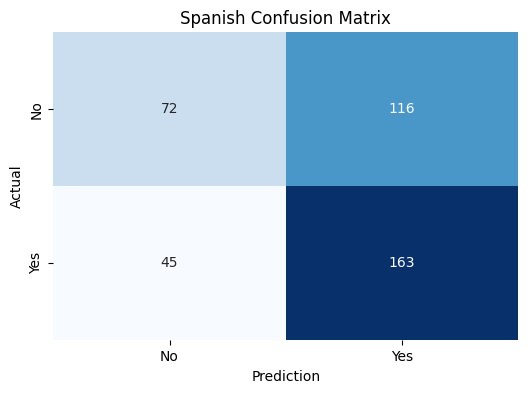

In [25]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    conf_matrix_es,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Spanish Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")

plt.show()

In [26]:
fpositive_es, fnegative_es = false_positive_false_negative(
    y_true=val_dataset_es.labels,
    y_pred=preds_es,
    pred_probs=probs_es,
    texts=val_dataset_es.texts
)

print("False positive:", len(fpositive_es))
for s in fpositive_es:
    print("**", s)

print("\n\nFalse negative:", len(fnegative_es))
for s in fnegative_es:
    print("**", s)

False positive: 116
** (0.52885187, 'zorra feliz')
** (0.64025587, 'TOMA YA! GOOOL. TE HE FOLLAO!! GUT tu no conoses a mi madre, niño rata A-Z NOTCHFAKE vuelve x favor como yo a tu madre xd TKM INENA')
** (0.6681113, 'En mi infancia las olas de calor las pasábamos viendo a Espinete en el sofá de escay y comiendo pipas. Flojos, que sois unos flojos. 00')
** (0.54391146, 'Cuando tu amigo lleva todo el día bebiendo y quiere conducir Estoy triste, debo ver a un hombre morir esta noche Pero le sale tan bien que hasta hace acrobacias Basura inutil Ese tiene pacto con el diablo')
** (0.52531374, 'NO HABRÁ UN PRÓXIMO GOLPE MW DE TU VIOLENCIA ME VOY A DEFENDER facebook/ecardsfeministas')
** (0.5974902, '- Como llevas la dieta Conchi?? Muy contenta, ya me han entrado los pantalones ne visto en elButanero.com')
** (0.7799991, 'ERES UNA GUARRA H HISTORY.COM memegenerator.es')
** (0.5274891, 'Juan Carlos Navarro NavarroTv - 21h *Suena tusa* Hombres: Muestren su talento chicas 22 1')
** (0.55787694,

In [27]:
#Show selected examples

selected_false_positives_es = [
    fpositive_es[7],
    fpositive_es[4]
]

selected_false_negatives_es = [
    fnegative_es[25],
    fnegative_es[7]
]

print("=== SELECTED FALSE POSITIVES ===\n")

for i, example in enumerate(selected_false_positives_es, 1):
    print(f"False Positive {i}")
    print("Confidence:", example[0])
    print("Text:", example[1])
    print()

print("\n=== SELECTED FALSE NEGATIVES ===\n")

for i, example in enumerate(selected_false_negatives_es, 1):
    print(f"False Negative {i}")
    print("Confidence:", example[0])
    print("Text:", example[1])
    print()

=== SELECTED FALSE POSITIVES ===

False Positive 1
Confidence: 0.5274891
Text: Juan Carlos Navarro NavarroTv - 21h *Suena tusa* Hombres: Muestren su talento chicas 22 1

False Positive 2
Confidence: 0.52531374
Text: NO HABRÁ UN PRÓXIMO GOLPE MW DE TU VIOLENCIA ME VOY A DEFENDER facebook/ecardsfeministas


=== SELECTED FALSE NEGATIVES ===

False Negative 1
Confidence: 0.51877975
Text: PAPI SIEMPRE ME MANDA A FREGAR LOS PLATOS.….. Corresponsabilidad Manzanares 38 MIENTRAS MI HERMANO JUEGA AL FORNITE

False Negative 2
Confidence: 0.57203865
Text: SI UN HOMBRE LE PEGA A UN TRAVESTI ¿SE CONSIDERA VIOLENCIA DE GÉNERO? cuantocabron.com



In [28]:
# Create Spanish explainers
shap_es = SHAPExplainer(model_es, tokenizer_es)
lime_es = LIMEExplainer(model_es, tokenizer_es)

# Create Spanish benchmark
bench_es = Benchmark(
    model=model_es,
    tokenizer=tokenizer_es,
    explainers=[shap_es, lime_es]
)

In [29]:
from IPython.display import display

# Analyse selected Spanish examples

for confidence, text in selected_false_positives_es + selected_false_negatives_es:

    print("=" * 100)
    print("Confidence:", confidence)
    print(text)

    explanations = bench_es.explain(
        text,
        target=1
    )

    explanations = deduplicate(explanations)

    display(bench_es.show_table(explanations))

Confidence: 0.5274891
Juan Carlos Navarro NavarroTv - 21h *Suena tusa* Hombres: Muestren su talento chicas 22 1


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,juan,carlos,navarro_1,navarro_2,##tv,-,21,##h,*_1,suena,tus,##a,*_2,hombres,:,muestre,##n,su,talento,chicas,22,1
Partition SHAP,0.02,0.03,0.05,0.06,0.00,0.02,0.04,0.05,0.00,0.02,0.03,0.03,-0.00,0.04,0.01,0.09,0.07,0.06,0.10,0.15,0.03,0.08
LIME,0.03,0.04,0.05,0.05,0.03,0.03,0.03,0.06,0.02,0.05,0.02,0.01,-0.02,0.06,0.03,0.11,0.03,0.03,0.07,0.12,0.04,0.08


Confidence: 0.52531374
NO HABRÁ UN PRÓXIMO GOLPE MW DE TU VIOLENCIA ME VOY A DEFENDER facebook/ecardsfeministas


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,no,habrá,un,próximo,golpe,m,##w,de,tu,violencia,me,voy,a,defender,facebook,/,ec,##ards,##fe,##minis,##tas
Partition SHAP,0.06,0.04,0.05,0.01,0.06,0.10,0.04,0.03,0.05,0.05,0.05,0.03,0.06,0.11,0.01,-0.02,0.02,0.03,0.12,0.06,0.01
LIME,0.03,0.04,0.06,0.00,0.02,0.04,0.03,0.05,0.05,0.07,0.04,0.04,0.04,0.11,0.03,-0.04,0.05,0.05,0.11,0.09,0.01


... (2 outputs left out)

Token,papi,siempre,me,manda,a,freg,##ar,los,platos,._1,[UNK],._2,._3,correspon,##sa,##bilidad,manzana,##res,3,##8,mientras,mi,hermano,juega,al,for,##ni,##te
Partition SHAP,0.02,0.02,0.02,0.08,0.06,0.07,0.04,0.05,0.03,0.05,-0.02,0.01,0.01,0.05,0.05,0.03,0.02,0.04,0.01,-0.01,0.03,0.02,0.02,0.00,0.05,0.09,0.09,-0.01
LIME,0.02,0.00,0.05,0.05,0.02,0.06,0.04,0.03,0.03,0.03,0.04,0.06,0.03,0.10,0.05,0.03,0.01,0.03,0.03,-0.03,0.04,0.02,0.03,0.01,0.03,0.09,0.06,0.00


Confidence: 0.57203865
SI UN HOMBRE LE PEGA A UN TRAVESTI ¿SE CONSIDERA VIOLENCIA DE GÉNERO? cuantocabron.com


Explainer:   0%|          | 0/2 [00:00<?, ?it/s]

Token,si,un_1,hombre,le,pega,a,un_2,traves,##ti,¿,se,considera,violencia,de,género,?,cuanto,##cab,##ron,.,com
Partition SHAP,-0.00,0.00,0.02,0.01,0.04,0.01,0.02,0.06,0.05,0.01,0.04,0.05,0.02,0.01,-0.01,0.01,0.11,0.16,0.04,0.07,-0.27
LIME,0.00,0.04,0.04,0.05,0.08,0.02,0.04,0.07,0.06,0.02,0.07,0.05,0.00,0.03,-0.04,0.01,-0.03,0.05,0.07,0.07,-0.16


## Spanish Model Analysis and Discussion

### Methodology

For the Spanish task, we followed the same methodology used previously for the English dataset. First, the required libraries were imported, including `transformers`, `torch`, `scikit-learn`, `pandas`, and `ferret-xai`. The environment was configured to run on GPU whenever CUDA was available, otherwise CPU was used.

The Spanish pre-trained model was loaded using Hugging Face Transformers. In this case, the tokenizer and the sequence classification model were initialized from the fine-tuned Spanish checkpoint stored locally. The dataset was transformed into a custom `SexismDataset` class that tokenizes each meme text, applies padding and truncation, and converts labels into tensors compatible with PyTorch.

Two prediction approaches were implemented:

- `predict_op1`: using the Hugging Face `Trainer` API.
- `predict_op2`: using a manual `DataLoader` and inference loop.

Both approaches produced equivalent predictions, validating the implementation.

After obtaining predictions, several evaluation metrics were computed:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Classification report

Finally, false positives and false negatives were extracted in order to perform qualitative error analysis.

---

## Results

### Metrics

- Accuracy: **0.5934**
- Precision: **0.5842**
- Recall: **0.7837**
- F1-score: **0.6694**

The model achieved relatively high recall but lower precision. This means that the classifier tends to detect many sexist examples, but also incorrectly labels many non-sexist memes as sexist.

---

## Confusion Matrix Analysis

The confusion matrix shows:

- True Negatives: 72
- False Positives: 116
- False Negatives: 45
- True Positives: 163

The number of false positives is especially high. This indicates that the model is very sensitive to:
- gender-related vocabulary,
- offensive language,
- references to women or feminism,
- sexual expressions.

However, many of these examples are not actually sexist in context.

---

## False Positive Analysis

Several false positives demonstrate that the model frequently mistakes:
- irony,
- feminist discourse,
- social criticism,
- or colloquial vulgarity

for sexist content.

### Example 1
**Text:**  
*"UNA MUJER LIBRE ES JUSTO LO CONTRARIO A UNA MUJER FÁCIL"*

This sentence actually criticizes sexist stereotypes against women. Nevertheless, the model classified it as sexist because of the explicit references to women and gender concepts.

---

### Example 2
**Text:**  
*"NO HABRÁ UN PRÓXIMO GOLPE. DE TU VIOLENCIA ME VOY A DEFENDER"*

The meme condemns violence rather than promoting it. However, the model focused on aggressive vocabulary such as *“golpe”* and *“violencia”*.

---

### Example 3
**Text:**  
*"EL PATRIARCADO NOS OPRIME A TODOS"*

This is a political or ideological statement rather than sexist hate speech. The model incorrectly associated feminist terminology with sexism.

---

## False Negative Analysis

False negatives reveal that the classifier struggles with:
- implicit sexism,
- stereotypes,
- sarcasm,
- and contextual humor.

### Example 1
**Text:**  
*"PAPI SIEMPRE ME MANDA A FREGAR LOS PLATOS MIENTRAS MI HERMANO JUEGA AL FORNITE"*

This meme clearly reflects traditional sexist gender roles in domestic tasks. However, the model failed to detect sexism because the text does not contain explicit insults or aggressive wording.

---

### Example 2
**Text:**  
*"Cuando tu novia tiene la regla e intentas discutir algo con ella sin molestarla"*

The meme reinforces stereotypes about women’s emotions during menstruation, but the classifier interpreted it as non-sexist due to its humorous tone.

---

### Example 3
**Text:**  
*"¡CÁSATE Y SÉ SUMISA!"*

Despite containing explicit patriarchal discourse, the model still classified the meme as non-sexist. This suggests limitations in semantic understanding and contextual interpretation.

---

## Main Difficulties Encountered

During the implementation several technical issues appeared:

- Missing package dependencies in Google Colab.
- `HFValidationError` when loading local Hugging Face checkpoints.
- Incorrect dataframe column names such as `true_label`.
- Slow execution on CPU before GPU configuration.
- Ferret-XAI installation and compatibility problems.

These issues were progressively solved by:
- updating libraries,
- correcting local model paths,
- checking dataframe structure,
- and configuring Colab correctly.

---

## General Conclusions

The Spanish model achieved moderate performance but showed important weaknesses in contextual understanding.

Main observations:
- The model overpredicts sexism when gender-related words appear.
- It struggles with irony and humor.
- Implicit sexism is significantly harder to detect than explicit insults.
- Political or feminist discourse is frequently confused with misogynistic language.
- Vulgar language alone strongly biases the predictions.

Overall, transformer-based models are effective at capturing lexical patterns, but they still have difficulties understanding nuanced social context, sarcasm, and implicit stereotypes present in internet memes.


For the Spanish model, real false positive and false negative examples were also selected from the development set and analysed using SHAP and LIME.In the false positive *"Juan Carlos Navarro... Hombres: Muestren su talento chicas"*, the model gave importance to tokens such as *hombres*, *talento*, and *chicas*. This suggests that the classifier is highly sensitive to gender-related vocabulary, even when the text is not clearly sexist.In the false positive *"NO HABRÁ UN PRÓXIMO GOLPE... DE TU VIOLENCIA ME VOY A DEFENDER"*, the model focused on words such as *golpe*, *violencia*, *defender*, and the fragment related to *feministas*. However, the text is actually an anti-violence message. Therefore, the error seems to come from the model confusing discourse about violence with sexist content.For false negatives, the example *"PAPI SIEMPRE ME MANDA A FREGAR LOS PLATOS... MIENTRAS MI HERMANO JUEGA AL FORNITE"* is especially relevant. The model gave some importance to words like *manda*, *fregar*, *platos*, and *hermano*, but it still failed to classify it as sexist. This shows that the model struggles with implicit sexism based on traditional gender roles.The example *"SI UN HOMBRE LE PEGA A UN TRAVESTI ¿SE CONSIDERA VIOLENCIA DE GÉNERO?"* also reveals limitations. SHAP and LIME highlighted words related to *hombre*, *pega*, *travesti*, *violencia*, and *género*, but the model still failed to correctly classify the example. This suggests that complex or controversial gender-related contexts are difficult for the classifier.---### General conclusionOverall, the explainability analysis shows that both models rely heavily on surface-level lexical cues. Words related to gender, violence, feminism, or sexual content strongly influence the predictions.The models work better when sexism is explicit, but they struggle with:- irony,- memes,- implicit stereotypes,- ambiguous gender discourse,- and contextual humour.SHAP and LIME were useful because they made the models' decisions more transparent. They helped identify which tokens were responsible for incorrect predictions and confirmed that many errors come from over-reliance on isolated keywords rather than full contextual understanding.
